# Testing the KPIs and understanding the statistical model (notebook 02b)

**Project:** Why Britain voted Leave, and where the explanation breaks

**Why this notebook:** notebook 02 calculated the **KPIs** (for example, "the fifth of areas with the most graduates voted 24.1 points less Leave than the fifth with the fewest") and built a **regression model**. But two questions were left open:

1. **Are the KPI gaps solid**, or could they be produced by chance? We never tested them formally.
2. **What exactly does the statistical model do**, and how should we read it?

This notebook answers both, step by step, in simple words.

**Where this notebook fits in the project**

| Notebook | What it does |
|---|---|
| 01 Data exploration | Finds the patterns with charts and maps |
| 02 Statistical tests | Tests the patterns, calculates the KPIs, builds the regression |
| **02b KPI tests and model (this one)** | Tests the KPIs and explains the model in detail |
| 03 Scotland in depth | Compares Scotland's 2016 EU vote with its 2014 independence vote |
| 04 What-if scenario (optional) | Shows how a future independence vote could spread across councils |
| Tableau dashboards | Present the results |

**Reminder:** every result describes **areas, not individual voters**.

## Key ideas in simple words

| Idea | Meaning |
|---|---|
| **KPI gap** | The Leave share in the top fifth of areas minus the Leave share in the bottom fifth, for one characteristic (graduates, pay...). |
| **Quintile (fifth)** | We sort the 380 areas by a characteristic and cut them into 5 equal groups of 76. Group 1 = lowest 20%, group 5 = highest 20%. |
| **Null hypothesis** | The "boring" assumption a test tries to reject: here, "the top and bottom fifth voted the same". |
| **p-value** | If the boring assumption were true, how often would chance alone give a gap this big? Below 0.05 = probably not chance. |
| **Bootstrap** | We resample our own areas thousands of times and recalculate the gap each time, to see how much it could move. The middle 95% of the results is the **confidence interval**. |
| **Confidence interval (95% CI)** | The range where the true gap probably sits. If it **doesn't include 0**, the gap is solid. |
| **Effect size (Cohen's d)** | How big the difference is, in "standard deviations". About 0.2 small, 0.5 medium, 0.8 large, above 1.2 very large. |
| **Regression** | A model that predicts the Leave share from several characteristics **at the same time**, so we can see the effect of each one **holding the others fixed**. |
| **Coefficient** | In a regression: how much the Leave share changes when one characteristic goes up by 1 point, the others staying the same. |
| **Residual** | Real Leave share minus the model's prediction. Positive = the area voted more Leave than expected. |
| **Confounding** | When two characteristics move together (older areas also have fewer graduates), one can look important only because of the other. |

## 1. Setup and data

We use the clean table from notebook 01 (`gb_areas_clean.csv`), the same Python tools as before, and a fixed random seed so the bootstrap gives the same results every time.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b5b3ac"
rng = np.random.default_rng(42)

DATA_DIR = Path("../data")  # the data folder of this repository
areas = pd.read_csv(DATA_DIR / "gb_areas_clean.csv")
areas["group"] = np.select([areas["nation"] == "Scotland", areas["region"] == "London"],
                           ["Scotland", "London"], "Rest of GB")
print(areas.shape)

(380, 27)


## 2. Rebuild the KPIs

**What this cell does**

1. For each characteristic, it cuts the 380 areas into **5 equal groups** (`pd.qcut`), from group 1 (lowest) to group 5 (highest).
2. In each group, it calculates the **Leave share from total votes** (all Leave votes divided by all valid votes), so big areas count more, as in the real result.
3. The **KPI gap** = group 5 minus group 1.

These are the same numbers as in notebook 02 and in Tableau, so we know we're testing the right thing.

In [2]:
KPIS = {"pct_degree": "Graduate share", "pct_ab": "Social grade AB", "median_weekly_pay": "Median weekly pay",
        "pct_65plus": "Aged 65+", "claimant_rate": "Claimant rate", "ukip_2014_pct": "UKIP vote 2014"}

for column in KPIS:
    areas[f"q_{column}"] = pd.qcut(areas[column], 5, labels=[1, 2, 3, 4, 5]).astype("float")


def weighted_leave(df):
    # Leave share of all valid votes in a group of areas
    return 100 * df["leave_votes"].sum() / df["valid_votes"].sum()


def kpi_gap(df, column):
    top = df[df[f"q_{column}"] == 5]
    bottom = df[df[f"q_{column}"] == 1]
    return weighted_leave(top) - weighted_leave(bottom)


table = pd.DataFrame({label: [weighted_leave(areas[areas[f"q_{c}"] == q]) for q in range(1, 6)]
                      for c, label in KPIS.items()}, index=[f"group {q}" for q in range(1, 6)]).T
table["gap (5 - 1)"] = table["group 5"] - table["group 1"]
display(table.round(1))

,group 1,group 2,group 3,group 4,group 5,gap (5 - 1)
Graduate share,63.3,55.2,53.2,50.4,39.2,-24.1
Social grade AB,60.4,54.7,54.3,49.4,42.0,-18.5
Median weekly pay,59.8,55.3,50.9,50.1,44.7,-15.1
Aged 65+,44.6,54.1,55.1,53.8,56.9,12.3
Claimant rate,50.7,53.1,51.4,53.5,51.9,1.2
UKIP vote 2014,38.2,50.8,55.1,59.1,62.7,24.5


**What we see:** the same KPIs as before: graduates **-24.1**, social grade AB **-18.5**, pay **-15.1**, age 65+ **+12.3**, claimant rate **+1.2**, UKIP 2014 **+24.5** points.

Now we test them.

## 3. Test 1: a confidence interval for each gap (bootstrap)

**The question:** if we had a slightly different set of areas, how much could each gap change?

**How the bootstrap works, step by step**

1. Take the 76 areas of group 1 and the 76 areas of group 5.
2. Draw 76 areas **at random, with replacement**, from each group. Some areas are picked twice, some not at all. It's a "new version" of our data.
3. Recalculate the gap on this new version.
4. Repeat **5,000 times**. We get 5,000 possible gaps.
5. The **middle 95%** of these 5,000 gaps is the **95% confidence interval**.

**How to read it:** if the interval **doesn't include 0**, the gap is solid: even with a different set of areas, it would still be there.

In [3]:
def bootstrap_gap(column, n_boot=5000):
    df = areas.dropna(subset=[f"q_{column}"])
    top = df[df[f"q_{column}"] == 5]
    bottom = df[df[f"q_{column}"] == 1]
    gaps = []
    for _ in range(n_boot):
        t = top.iloc[rng.integers(0, len(top), len(top))]
        b = bottom.iloc[rng.integers(0, len(bottom), len(bottom))]
        gaps.append(weighted_leave(t) - weighted_leave(b))
    return np.percentile(gaps, [2.5, 97.5])


rows = []
for column, label in KPIS.items():
    low, high = bootstrap_gap(column)
    rows.append({"KPI": label, "gap": kpi_gap(areas, column), "ci_low": low, "ci_high": high,
                 "includes 0?": "yes" if low <= 0 <= high else "no"})
ci_table = pd.DataFrame(rows)
display(ci_table.round(1))

,KPI,gap,ci_low,ci_high,includes 0?
0,Graduate share,-24.1,-27.2,-21.0,no
1,Social grade AB,-18.5,-21.8,-14.9,no
2,Median weekly pay,-15.1,-18.5,-11.6,no
3,Aged 65+,12.3,9.0,15.5,no
4,Claimant rate,1.2,-2.2,4.5,yes
5,UKIP vote 2014,24.5,21.9,27.1,no


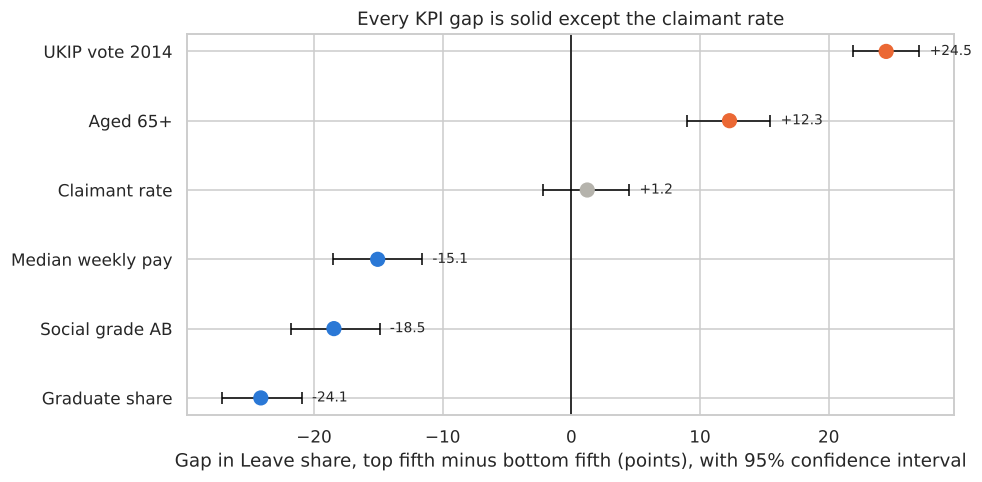

In [4]:
# Chart: each gap with its confidence interval
order = ci_table.sort_values("gap")
fig, ax = plt.subplots(figsize=(9, 4.5))
colours = [GREY if row["includes 0?"] == "yes" else (ORANGE if row["gap"] > 0 else BLUE) for _, row in order.iterrows()]
ax.errorbar(order["gap"], order["KPI"], xerr=[order["gap"] - order["ci_low"], order["ci_high"] - order["gap"]],
            fmt="none", ecolor="black", capsize=4, linewidth=1)
ax.scatter(order["gap"], order["KPI"], color=colours, s=80, zorder=3)
ax.axvline(0, color="black", linewidth=1)
for _, row in order.iterrows():
    ax.text(row["ci_high"] + 0.8, row["KPI"], f"{row['gap']:+.1f}", va="center", fontsize=9)
ax.set_xlabel("Gap in Leave share, top fifth minus bottom fifth (points), with 95% confidence interval")
ax.set_title("Every KPI gap is solid except the claimant rate")
plt.show()

**What we see**

- **Graduates:** -24.1 points, interval **-27.2 to -21.0**. Far from 0: very solid.
- **UKIP 2014** (+21.9 to +27.1), **social grade AB** (-21.8 to -14.9), **pay** (-18.5 to -11.6) and **age 65+** (+9.0 to +15.5): all solid.
- **Claimant rate:** +1.2 points, interval **-2.2 to +4.5**. It **includes 0**, so we **can't say** the most and least unemployed areas voted differently.

**In simple words:** the education, pay, social grade, age and UKIP gaps are real. The claimant-rate gap could be zero.

## 4. Test 2: is the difference between the top and bottom fifth significant? (Welch t-test + effect size)

**The question:** did the 76 areas of group 5 vote differently from the 76 areas of group 1?

**The tests**

- **Welch t-test:** compares the **average Leave share** of the two groups. Null hypothesis: "the two groups have the same average". We use Welch's version because it doesn't assume the two groups have the same spread (notebook 02 showed spreads differ).
- **Cohen's d:** the size of the difference, in standard deviations. It tells us **how big**, not just whether it's real.

**Note:** this test uses each area's own Leave share (every area counts once), while the KPI uses total votes. The two give the same picture; the test checks the pattern isn't driven by a few big areas.

In [5]:
rows = []
for column, label in KPIS.items():
    df = areas.dropna(subset=[f"q_{column}"])
    top = df.loc[df[f"q_{column}"] == 5, "leave_pct"]
    bottom = df.loc[df[f"q_{column}"] == 1, "leave_pct"]
    t = stats.ttest_ind(top, bottom, equal_var=False)
    d = (top.mean() - bottom.mean()) / np.sqrt((top.var() + bottom.var()) / 2)
    rows.append({"KPI": label, "mean group 1": bottom.mean(), "mean group 5": top.mean(),
                 "t": t.statistic, "p_value": t.pvalue, "cohens_d": d})
ttest_table = pd.DataFrame(rows)
display(ttest_table.round(3))

,KPI,mean group 1,mean group 5,t,p_value,cohens_d
0,Graduate share,63.231,40.631,-15.947,0.000,-2.587
1,Social grade AB,60.326,43.280,-10.827,0.000,-1.756
2,Median weekly pay,60.081,45.732,-9.068,0.000,-1.471
3,Aged 65+,45.850,56.543,6.189,0.000,1.004
4,Claimant rate,51.021,53.311,1.417,0.159,0.226
5,UKIP vote 2014,38.004,63.345,23.893,0.000,3.876


**What we see**

- **Graduates:** p ≈ 5 × 10⁻³⁴ and **d = -2.6**: an **extremely large** difference. The two groups barely overlap.
- **UKIP 2014** (d = +3.9), **social grade AB** (-1.8), **pay** (-1.5): very large.
- **Age 65+:** d = +1.0, large.
- **Claimant rate:** p = **0.16**, d = 0.2: **not significant**, a small difference that could be chance.

**In simple words:** areas with the most graduates and the fewest graduates voted in very different ways. Areas with the most and the fewest unemployed did not.

## 5. Test 3: does Leave change steadily across the five groups? (trend tests)

The gap only compares the two **extreme** groups. We also want to know whether the Leave share moves **steadily** across all five groups, or only at the ends.

**The tests**

- **Kruskal-Wallis:** do the five groups differ at all? It compares their medians and doesn't need bell-shaped data. Null hypothesis: "all five groups voted the same".
- **Spearman ρ between group number (1 to 5) and Leave share:** is there a **steady trend**? Close to -1 or +1 = a steady fall or rise; close to 0 = no trend.

,KPI,kruskal_H,kruskal_p,trend_rho,trend_p
0,Graduate share,203.9909,0.000,-0.7270,0.0000
1,Social grade AB,123.9172,0.000,-0.5516,0.0000
2,Median weekly pay,79.2570,0.000,-0.4511,0.0000
3,Aged 65+,32.1119,0.000,0.2350,0.0000
4,Claimant rate,15.3512,0.004,0.1626,0.0015
5,UKIP vote 2014,259.4891,0.000,0.8203,0.0000


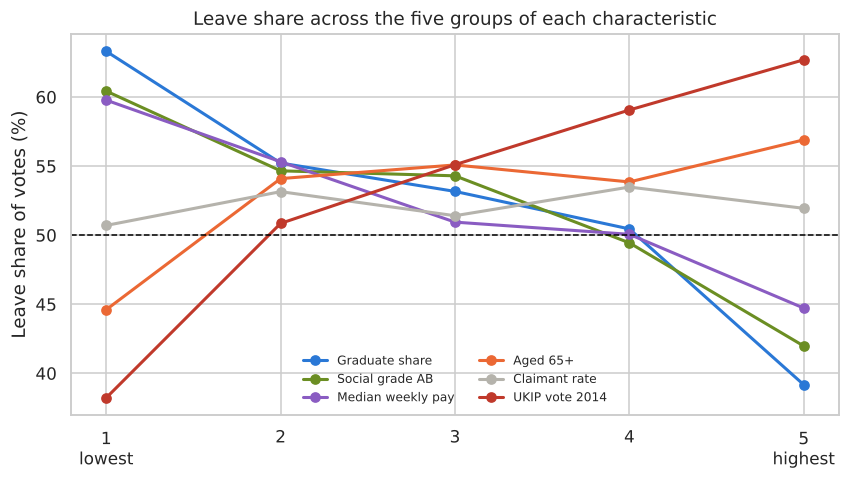

In [6]:
rows = []
for column, label in KPIS.items():
    df = areas.dropna(subset=[f"q_{column}"])
    kw = stats.kruskal(*[g["leave_pct"] for _, g in df.groupby(f"q_{column}")])
    rho = stats.spearmanr(df[f"q_{column}"], df["leave_pct"])
    rows.append({"KPI": label, "kruskal_H": kw.statistic, "kruskal_p": kw.pvalue,
                 "trend_rho": rho.statistic, "trend_p": rho.pvalue})
trend_table = pd.DataFrame(rows)
display(trend_table.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
for (column, label), colour in zip(KPIS.items(), [BLUE, "#6b8e23", "#8a5cc2", ORANGE, GREY, "#c0392b"]):
    shares = [weighted_leave(areas[areas[f"q_{column}"] == q]) for q in range(1, 6)]
    ax.plot(range(1, 6), shares, marker="o", label=label, color=colour, linewidth=2)
ax.axhline(50, color="black", linestyle="--", linewidth=1)
ax.set_xticks(range(1, 6), ["1\nlowest", "2", "3", "4", "5\nhighest"])
ax.set_ylabel("Leave share of votes (%)")
ax.set_title("Leave share across the five groups of each characteristic")
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.show()

**What we see**

- **Graduates:** a **steady fall** across all five groups (ρ = -0.73). The more graduates, the less Leave, at every step, not just at the extremes.
- **UKIP 2014:** a steady rise (ρ = +0.82).
- **Social grade AB** (-0.55) and **pay** (-0.45): steady falls, a bit weaker.
- **Age 65+:** a weak trend (ρ = +0.23). The jump is mostly between group 1 (young, city areas) and the rest.
- **Claimant rate:** ρ = +0.16. Formally significant, but **very weak**, and the gap itself isn't (section 3). There's almost no relationship.

**Why can a test be "significant" but the effect tiny?** With 380 areas, even a small trend gets a small p-value. That's why we always look at the **size** (ρ, the gap, Cohen's d) as well as the p-value.

## 6. Summary of the KPI tests

| KPI | Gap | 95% CI | Gap significant? | Size | Steady trend? |
|---|---|---|---|---|---|
| Graduate share | **-24.1** | -27.2 to -21.0 | Yes (p < 0.001) | Extremely large (d = -2.6) | Yes, strong (ρ = -0.73) |
| UKIP 2014 | +24.5 | +21.9 to +27.1 | Yes | Extremely large (d = 3.9) | Yes, very strong (ρ = 0.82) |
| Social grade AB | -18.5 | -21.8 to -14.9 | Yes | Very large (d = -1.8) | Yes (ρ = -0.55) |
| Median weekly pay | -15.1 | -18.5 to -11.6 | Yes | Very large (d = -1.5) | Yes (ρ = -0.45) |
| Aged 65+ | +12.3 | +9.0 to +15.5 | Yes | Large (d = 1.0) | Weak (ρ = 0.23) |
| Claimant rate | +1.2 | -2.2 to +4.5 | **No** (p = 0.16) | Small (d = 0.2) | Very weak (ρ = 0.16) |

**Conclusion:** the KPIs hold up. Education, UKIP, social grade and pay show large, solid, steady gaps. Age shows a real but smaller gap. **Unemployment shows none.**

**But a KPI looks at one characteristic at a time.** Graduates, pay, social grade and age move together. So which one really matters? That's the job of the regression model.

## 7. Understanding the statistical model (regression)

### 7.1 The idea in one sentence

A **linear regression** finds the best formula of the form

> **Predicted Leave share = starting value + (effect of graduates × graduate share) + (effect of age × share aged 65+) + ...**

"Best" means the formula whose predictions are, on average, **closest to the real results** of the 380 areas.

### 7.2 Why we need it: the KPIs can mislead

The age gap is +12.3 points. But areas with many older people **also** tend to have somewhat fewer graduates (correlation -0.25). So is it age, or is it education? A KPI can't tell. A regression can, because it estimates each effect **while holding the others fixed**: it compares areas that have the **same** graduate share but **different** age profiles.

**An everyday example:** ice cream sales and sunburns rise together. A regression with temperature in it would show that sunburns don't cause ice cream sales: both come from hot weather. Here, education may be the "hot weather" behind the age gap.

### 7.3 Let's check this confounding directly

**What this cell does:** it measures how strongly the characteristics move together (correlation).

In [7]:
display(areas[["pct_degree", "pct_ab", "median_weekly_pay", "pct_65plus", "claimant_rate", "ukip_2014_pct"]]
        .corr().round(2))

,pct_degree,pct_ab,median_weekly_pay,pct_65plus,claimant_rate,ukip_2014_pct
pct_degree,1.00,0.92,0.75,-0.25,-0.46,-0.50
pct_ab,0.92,1.00,0.82,-0.14,-0.61,-0.24
median_weekly_pay,0.75,0.82,1.00,-0.27,-0.42,-0.26
pct_65plus,-0.25,-0.14,-0.27,1.00,-0.29,0.45
claimant_rate,-0.46,-0.61,-0.42,-0.29,1.00,-0.17
ukip_2014_pct,-0.50,-0.24,-0.26,0.45,-0.17,1.00


**How to read it:** each cell is the correlation between two characteristics. Close to +1 or -1 = they move together strongly.

**What we see:** graduate share moves strongly with social grade AB and with pay. So the education, social grade and pay KPIs partly measure **the same thing**. The model has to separate them.

### 7.4 Fit the model

**Model A (demographics):** Leave share ~ graduate share + share aged 65+ + share aged 18-29 + claimant rate.

**Choices, and why**

- **One education measure only** (graduate share). Social grade AB and pay repeat the same information (section 7.3), and putting them all in makes the effects unstable (notebook 02, VIF).
- **Weighted by valid votes**, so big areas count more, like the real result.
- **Robust (HC3) standard errors**: they stay correct even though the model's errors are bigger for some areas than others (notebook 02, Breusch-Pagan).

The helper function below does the maths. You don't need to follow every line: it returns the coefficients, their confidence intervals and the R².

In [8]:
def fit_ols(data, y, X, weight="valid_votes"):
    d = data[[y, weight] + X].dropna()
    Xm = np.column_stack([np.ones(len(d)), d[X].to_numpy()])
    w = (d[weight] / d[weight].mean()).to_numpy()
    sw = np.sqrt(w)
    Xw, yw = Xm * sw[:, None], d[y].to_numpy() * sw
    beta = np.linalg.lstsq(Xw, yw, rcond=None)[0]
    fitted = Xm @ beta
    resid = d[y].to_numpy() - fitted
    XtX_inv = np.linalg.inv(Xw.T @ Xw)
    h = np.einsum("ij,jk,ik->i", Xw, XtX_inv, Xw)
    meat = (Xw * ((resid * sw) / (1 - h))[:, None] ** 2).T @ Xw
    se = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv))
    r2 = 1 - np.sum(w * resid ** 2) / np.sum(w * (d[y] - np.average(d[y], weights=w)) ** 2)
    t = beta / se
    table = pd.DataFrame({"coefficient": beta, "ci_low": beta - 1.96 * se, "ci_high": beta + 1.96 * se,
                          "p_value": 2 * stats.t.sf(np.abs(t), len(d) - len(beta))}, index=["starting value"] + X)
    return table, pd.Series(fitted, index=d.index), pd.Series(resid, index=d.index), r2


X_A = ["pct_degree", "pct_65plus", "pct_18_29", "claimant_rate"]
coefs_A, fitted_A, resid_A, r2_A = fit_ols(areas, "leave_pct", X_A)
print(f"Model A: weighted R² = {r2_A:.2f}  (the model explains {100 * r2_A:.0f}% of the differences between areas)")
display(coefs_A.round(3))

Model A: weighted R² = 0.72  (the model explains 72% of the differences between areas)


,coefficient,ci_low,ci_high,p_value
starting value,97.135,88.040,106.229,0.000
pct_degree,-1.220,-1.336,-1.104,0.000
pct_65plus,-0.048,-0.279,0.183,0.684
pct_18_29,-0.382,-0.607,-0.157,0.001
claimant_rate,-2.973,-4.047,-1.900,0.000


### 7.5 How to read the coefficients

Each row answers: **"if this characteristic goes up by 1 point, and the others stay the same, how does the Leave share change?"**

- **Graduate share: about -1.22.** One extra point of graduates goes with **1.2 points less Leave**, with age and claimant rate held fixed. The interval stays far from 0, and p is tiny: a strong, solid effect. Over the real range (from about 14% to 40% graduates in most areas), that's a difference of about 30 points of Leave.
- **Aged 65+: close to 0, p ≈ 0.7.** Once we know the graduate share, **age adds almost nothing**. So the +12.3-point age KPI was mostly **education in disguise**: older areas tend to have fewer graduates.
- **Aged 18-29: about -0.38.** A small effect: younger areas voted slightly less Leave.
- **Claimant rate: about -3.0, negative!** On its own the claimant KPI was +1.2 (not significant). With graduates held fixed, more claimants go with slightly **less** Leave. This is because many high-claimant areas are in Scotland and big cities, which voted Remain for other reasons. A warning sign that the model mixes up places, which section 8 confirms.
- **Starting value (intercept):** the predicted Leave share for an imaginary area where every characteristic is 0. It has no real meaning by itself; it just positions the formula.

**R² ≈ 0.72:** these four characteristics together explain about **72%** of the differences between areas. The other 28% come from things not in the model.

### 7.6 A worked example: how the model predicts one area

**What this cell does:** it takes four real areas, multiplies each characteristic by its coefficient, adds everything up, and compares the prediction with the real result.

In [9]:
examples = areas[areas["area"].isin(["Hartlepool", "Cambridge", "Glasgow City", "Boston"])]
for _, row in examples.iterrows():
    parts = coefs_A.loc["starting value", "coefficient"]
    text = f"{coefs_A.loc['starting value', 'coefficient']:.1f}"
    for x in X_A:
        parts += coefs_A.loc[x, "coefficient"] * row[x]
        text += f" + ({coefs_A.loc[x, 'coefficient']:.2f} × {row[x]:.1f})"
    print(f"{row['area']}:")
    print(f"  prediction = {text}")
    print(f"             = {parts:.1f}% Leave   |   real: {row['leave_pct']:.1f}%   |   residual: {row['leave_pct'] - parts:+.1f}\n")

Hartlepool:
  prediction = 97.1 + (-1.22 × 17.6) + (-0.05 × 16.9) + (-0.38 × 15.2) + (-2.97 × 4.7)
             = 55.0% Leave   |   real: 69.6%   |   residual: +14.5

Cambridge:
  prediction = 97.1 + (-1.22 × 47.3) + (-0.05 × 11.8) + (-0.38 × 30.8) + (-2.97 × 0.7)
             = 25.0% Leave   |   real: 26.2%   |   residual: +1.2

Boston:
  prediction = 97.1 + (-1.22 × 15.1) + (-0.05 × 19.7) + (-0.38 × 15.1) + (-2.97 × 1.5)
             = 67.5% Leave   |   real: 75.6%   |   residual: +8.1

Glasgow City:
  prediction = 97.1 + (-1.22 × 25.9) + (-0.05 × 13.9) + (-0.38 × 22.3) + (-2.97 × 3.2)
             = 46.8% Leave   |   real: 33.4%   |   residual: -13.4



**What we see**

- **Cambridge** has a very high graduate share, so the model predicts low Leave, close to the real result.
- **Boston** has few graduates, so the model predicts high Leave. The real result was even higher.
- **Hartlepool:** the model expects 55%, but it voted almost 70% Leave: about 15 points **more** than its demographics suggest.
- **Glasgow:** the model expects about 47% Leave, close to the national average, but Glasgow voted only 33%: a residual of about -13 points. That's the Scotland effect.

### 7.7 Which factor matters most? (standardised effects)

Coefficients use different units (a point of graduates isn't comparable to a point of claimant rate). To compare them, we measure each effect for a **typical change**: one standard deviation, the usual spread of that characteristic across areas.

,standardised effect
pct_degree,-0.90
claimant_rate,-0.25
pct_18_29,-0.15
pct_65plus,-0.02


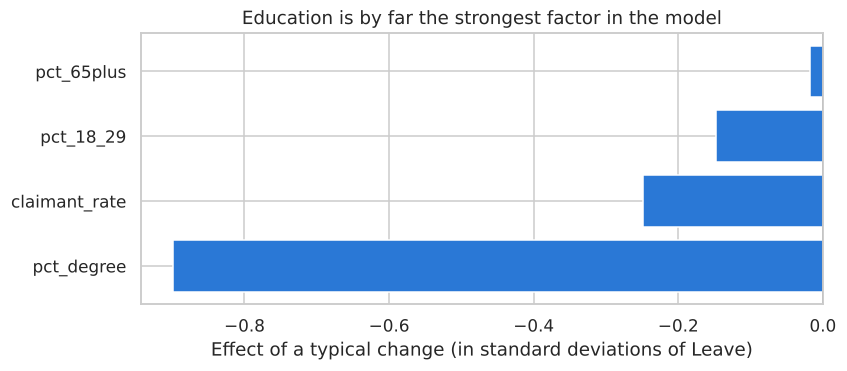

In [10]:
sd_y = areas["leave_pct"].std()
standardised = pd.Series({x: coefs_A.loc[x, "coefficient"] * areas[x].std() / sd_y for x in X_A},
                         name="standardised effect").sort_values()
display(standardised.round(2).to_frame())

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(standardised.index, standardised.values, color=[BLUE if v < 0 else ORANGE for v in standardised.values])
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Effect of a typical change (in standard deviations of Leave)")
ax.set_title("Education is by far the strongest factor in the model")
plt.show()

**What we see:** graduate share has by far the largest effect (about -0.9): a typical difference in graduates moves the Leave share by almost one full typical difference in Leave. The others are much smaller. Age 65+ is close to zero.

## 8. Where the model breaks: the residuals

The model explains 72% of the differences. **Where does it fail?** We look at the **residuals** (real minus predicted) by group.

,count,mean,std,t_test_p
group,,,,
London,33,2.81,5.79,8.885950e-03
Rest of GB,315,1.32,3.52,1.365738e-10
Scotland,32,-14.61,5.27,2.746858e-16


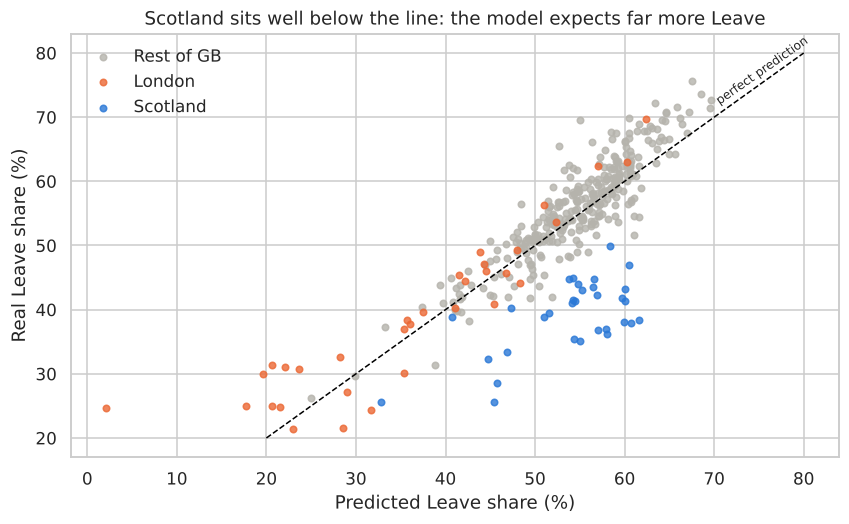

In [11]:
areas["resid_A"] = resid_A
summary = areas.groupby("group")["resid_A"].agg(["count", "mean", "std"]).round(2)
summary["t_test_p"] = [stats.ttest_1samp(areas.loc[areas["group"] == g, "resid_A"], 0).pvalue for g in summary.index]
display(summary)

fig, ax = plt.subplots(figsize=(9, 5))
for g, colour in [("Rest of GB", GREY), ("London", ORANGE), ("Scotland", BLUE)]:
    m = areas["group"] == g
    ax.scatter(fitted_A[m], areas.loc[m, "leave_pct"], s=18, color=colour, alpha=0.8, label=g)
ax.plot([20, 80], [20, 80], color="black", linewidth=1, linestyle="--")
ax.text(70, 72, "perfect prediction", fontsize=8, rotation=35)
ax.set_xlabel("Predicted Leave share (%)")
ax.set_ylabel("Real Leave share (%)")
ax.set_title("Scotland sits well below the line: the model expects far more Leave")
ax.legend(frameon=False)
plt.show()

**How to read the chart:** each dot is an area. Dots **on the dashed line** are perfectly predicted. Dots **below** voted less Leave than predicted; **above**, more.

**What we see**

- **Scotland:** the residuals average about **-14.6 points** (p < 0.001). The blue dots all sit well below the line. With the same graduates, age and unemployment, Scottish councils voted about 15 points less Leave. **Demographics can't explain Scotland.**
- **London:** about **+2.8 points**: small. London's Remain vote is mostly explained by its demographics (many graduates, young people).
- **Rest of GB:** about **+1.3 points** on average. Slightly above zero, because the model is fitted on all areas together and Scotland's big negative errors pull the line down a little for everyone else.

This is the project's key result: **education explains much of the Leave vote, and Scotland is where that explanation breaks**. Notebook 03 explores why.

## 9. The whole notebook in simple words

1. **The KPIs hold up.** We tested each one three ways (a confidence interval, a comparison of the top and bottom fifth, and a trend test). Education, UKIP, social grade, pay and age show real gaps. The **claimant rate doesn't**: its gap could be zero.
2. **But the KPIs overlap.** Graduates, social grade and pay move together, and older areas tend to have fewer graduates. So a KPI alone can make a characteristic look more important than it is.
3. **The regression separates them.** Holding the others fixed, **education is by far the strongest factor**: one extra point of graduates means 1.2 points less Leave. **Age adds almost nothing** once education is known: the age KPI was mostly education in disguise.
4. **The model explains about 72%** of the differences between areas.
5. **Where it breaks: Scotland.** The model expects about 15 points more Leave in Scotland than Scotland actually voted. London, on the other hand, is mostly explained by its demographics.

**For the presentation:** *"The KPIs show big gaps for education, pay and age. The model shows that education is the one that really matters, and that Scotland is the place where it stops working."*

**Next:** the Tableau dashboards, then the machine-learning model, which tests the same idea on regions the model has never seen.